# Unit 5 Jaccard Distance/Dissimilarity Calculations
This notebook works out the three Jaccard distances asked for in the Unit 5 e-Portfolio brief. I ran it in Google Colab.

## Scope and coding
The table of three patients is typed in from the brief, so there is no data file to load. I followed the brief's coding: Y and P become 1, N and A become 0. Name is an identifier and Gender is a symmetric attribute, so both are left out of the Jaccard calculation. I check the counts three ways (by formula, with Python sets and with SciPy) and then run the sensitivity checks in Table 3 of my report: treating A as missing, simple-matching distance, and adding Gender.

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) in Google Colab on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) in Google Colab on 30 October 2026 at 18:44 UTC


In [2]:
from pathlib import Path
from fractions import Fraction
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.spatial.distance import jaccard, pdist, squareform
OUT = Path.cwd() / 'Unit5_ePortfolio_Exports'
OUT.mkdir(exist_ok=True)
versions = {name: mod.__version__ for name, mod in
            [('numpy', np), ('pandas', pd), ('scipy', scipy), ('matplotlib', matplotlib)]}
print('Package versions:', versions)

Package versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'matplotlib': '3.10.0'}


## Step 1: the brief's table

In [3]:
records = [['Name', 'Gender', 'Fever', 'Cough', 'Test-1', 'Test-2', 'Test-3', 'Test-4'],
           ['Jack', 'M', 'Y', 'N', 'P', 'N', 'N', 'A'],
           ['Mary', 'F', 'Y', 'N', 'P', 'A', 'P', 'N'],
           ['Jim',  'M', 'Y', 'P', 'N', 'N', 'N', 'A']]
raw = pd.DataFrame(records[1:], columns=records[0])
raw.to_csv(OUT / 'original_profiles.csv', index=False)
display(raw)

,Name,Gender,Fever,Cough,Test-1,Test-2,Test-3,Test-4
0,Jack,M,Y,N,P,N,N,A
1,Mary,F,Y,N,P,A,P,N
2,Jim,M,Y,P,N,N,N,A


## Step 2: coding the six features as 1 or 0
I stop the run if the table holds any letter other than Y, N, P or A, so that nothing is turned into 0 by mistake.

In [4]:
features = ['Fever', 'Cough', 'Test-1', 'Test-2', 'Test-3', 'Test-4']
mapping = {'Y': 1, 'P': 1, 'N': 0, 'A': 0}
letters = set(raw[features].to_numpy().ravel())
if not letters.issubset(mapping):
    raise ValueError(f'Unexpected letters in the table: {letters - set(mapping)}')
binary = raw.set_index('Name')[features].apply(lambda col: col.map(mapping)).astype(int)
binary.to_csv(OUT / 'binary_profiles.csv')
display(binary)

,Fever,Cough,Test-1,Test-2,Test-3,Test-4
Name,,,,,,
Jack,1,0,1,0,0,0
Mary,1,0,1,0,1,0
Jim,1,1,0,0,0,0


## Step 3: counting matches and working out the distance
For each pair, f11 counts features positive for both people, f10 and f01 those positive for one person only, and f00 those negative for both. Jaccard distance is (f10 + f01) / (f11 + f10 + f01), so f00 plays no part. I also work it out with Python sets (1 minus shared positives over all positives) and with SciPy, to check the formula.

In [5]:
pairs = [('Jack', 'Mary'), ('Jack', 'Jim'), ('Jim', 'Mary')]
rows = []
for first, second in pairs:
    u = binary.loc[first].to_numpy()
    v = binary.loc[second].to_numpy()
    f11 = int(np.sum((u == 1) & (v == 1)))
    f10 = int(np.sum((u == 1) & (v == 0)))
    f01 = int(np.sum((u == 0) & (v == 1)))
    f00 = int(np.sum((u == 0) & (v == 0)))
    first_set = {f for f in features if binary.loc[first, f] == 1}
    second_set = {f for f in features if binary.loc[second, f] == 1}
    rows.append({'pair': f'({first}, {second})',
                 'shared positives': ', '.join(sorted(first_set & second_set)),
                 'f11': f11, 'f10': f10, 'f01': f01, 'f00': f00,
                 'fraction': str(Fraction(f10 + f01, f11 + f10 + f01)),
                 'formula': (f10 + f01) / (f11 + f10 + f01),
                 'sets': 1 - len(first_set & second_set) / len(first_set | second_set),
                 'scipy': float(jaccard(u.astype(bool), v.astype(bool)))})
results = pd.DataFrame(rows)
results.to_csv(OUT / 'pairwise_calculations.csv', index=False)
display(results.round(2))

,pair,shared positives,f11,f10,f01,f00,fraction,formula,sets,scipy
0,"(Jack, Mary)","Fever, Test-1",2,0,1,3,1/3,0.33,0.33,0.33
1,"(Jack, Jim)",Fever,1,1,1,3,2/3,0.67,0.67,0.67
2,"(Jim, Mary)",Fever,1,1,2,2,3/4,0.75,0.75,0.75


## Step 4: checking the three methods agree
If the formula, the set method and SciPy disagree on any pair, this cell stops with an error.

In [6]:
assert np.allclose(results['formula'], results['sets'])
assert np.allclose(results['formula'], results['scipy'])
distance_matrix = pd.DataFrame(squareform(pdist(binary.to_numpy(dtype=bool), metric='jaccard')),
                               index=binary.index, columns=binary.index)
distance_matrix.to_csv(OUT / 'jaccard_distance_matrix.csv')
display(distance_matrix.round(2))
print('All three methods agree.')
print('Closest pair:', results.loc[results['formula'].idxmin(), 'pair'])
print('Least similar pair:', results.loc[results['formula'].idxmax(), 'pair'])

Name,Jack,Mary,Jim
Name,,,
Jack,0.00,0.33,0.67
Mary,0.33,0.00,0.75
Jim,0.67,0.75,0.00


All three methods agree.
Closest pair: (Jack, Mary)
Least similar pair: (Jim, Mary)


## Step 5: figure for the report

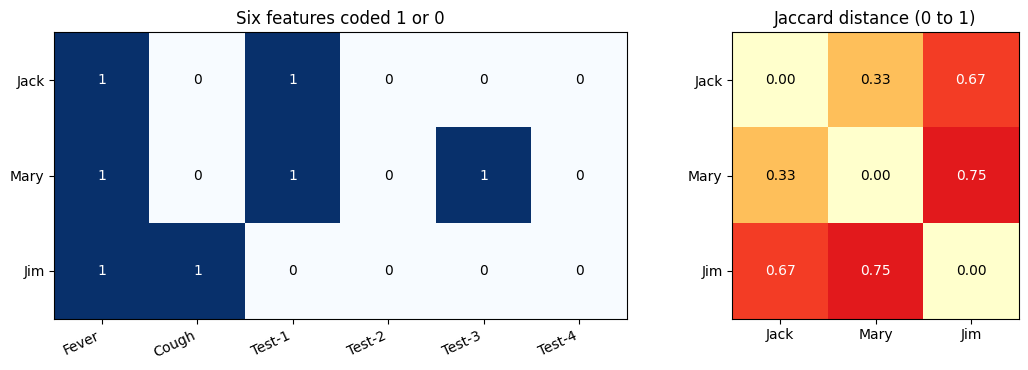

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1.4, 1]})
axes[0].imshow(binary.to_numpy(), cmap='Blues', vmin=0, vmax=1, aspect='auto')
axes[0].set_xticks(range(len(features)), features, rotation=25, ha='right')
axes[0].set_yticks(range(3), binary.index)
axes[0].set_title('Six features coded 1 or 0')
for i in range(3):
    for j in range(6):
        value = int(binary.iloc[i, j])
        axes[0].text(j, i, str(value), ha='center', va='center', color='white' if value else 'black')
axes[1].imshow(distance_matrix, cmap='YlOrRd', vmin=0, vmax=1)
axes[1].set_xticks(range(3), binary.index)
axes[1].set_yticks(range(3), binary.index)
axes[1].set_title('Jaccard distance (0 to 1)')
for i in range(3):
    for j in range(3):
        value = float(distance_matrix.iloc[i, j])
        axes[1].text(j, i, f'{value:.2f}', ha='center', va='center', color='white' if value > .6 else 'black')
fig.tight_layout()
fig.savefig(OUT / '01_binary_profiles_and_jaccard_distances.png', dpi=200, bbox_inches='tight')
plt.show()

## Step 6: sensitivity checks (Table 3 of my report)
The brief does not say what A means; it may mean "not tested". For "A missing", I leave out, for each pair, any feature where either person has A. Simple-matching distance divides the mismatches by all the features compared, so shared zeros count. "With Gender" adds Gender as one equally weighted symmetric feature, as a sensitivity check rather than a clinical choice: (f10 + f01 + g) / (f11 + f10 + f01 + 1), where g is 1 if the genders differ.

In [8]:
def jaccard_distance(u, v):
    f11 = np.sum((u == 1) & (v == 1))
    mismatches = np.sum(u != v)
    return Fraction(int(mismatches), int(f11 + mismatches))

def simple_matching_distance(u, v):
    return Fraction(int(np.sum(u != v)), len(u))

gender = raw.set_index('Name')['Gender']
letters_table = raw.set_index('Name')[features]
checks = []
for first, second in pairs:
    u = binary.loc[first].to_numpy()
    v = binary.loc[second].to_numpy()
    # Keep only the features where neither person has A
    keep = ((letters_table.loc[first] != 'A') & (letters_table.loc[second] != 'A')).to_numpy()
    f11 = int(np.sum((u == 1) & (v == 1)))
    mismatches = int(np.sum(u != v))
    g = int(gender[first] != gender[second])
    checks.append({'pair': f'({first}, {second})',
                   'Jaccard': jaccard_distance(u, v),
                   'Jaccard, A missing': jaccard_distance(u[keep], v[keep]),
                   'Simple-matching distance': simple_matching_distance(u, v),
                   'Simple-matching distance, A missing': simple_matching_distance(u[keep], v[keep]),
                   'With Gender': Fraction(mismatches + g, f11 + mismatches + 1)})
table3 = pd.DataFrame(checks).set_index('pair')
table3.astype(str).to_csv(OUT / 'sensitivity_checks_fractions.csv')
display(table3.astype(str))
display(table3.astype(float).round(2))

,Jaccard,"Jaccard, A missing",Simple-matching distance,"Simple-matching distance, A missing",With Gender
pair,,,,,
"(Jack, Mary)",1/3,1/3,1/6,1/4,1/2
"(Jack, Jim)",2/3,2/3,1/3,2/5,1/2
"(Jim, Mary)",3/4,3/4,1/2,3/4,4/5


,Jaccard,"Jaccard, A missing",Simple-matching distance,"Simple-matching distance, A missing",With Gender
pair,,,,,
"(Jack, Mary)",0.33,0.33,0.17,0.25,0.5
"(Jack, Jim)",0.67,0.67,0.33,0.40,0.5
"(Jim, Mary)",0.75,0.75,0.50,0.75,0.8


In [9]:
summary = {'run_by': 'Anne Dayer (student 39359)',
           'run_at_utc': datetime.now(timezone.utc).isoformat(timespec='minutes'),
           'execution_scope': 'Google Colab',
           'packages': versions, 'coding': mapping, 'features': features,
           'jaccard_distances': results[['pair', 'fraction']].to_dict('records'),
           'sensitivity_checks': table3.astype(str).reset_index().to_dict('records')}
(OUT / 'Unit5_results.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Outputs saved to', OUT)

Outputs saved to /content/Unit5_ePortfolio_Exports


## Interpretation and limitations
Jack and Mary are the closest pair: they share Fever and Test-1, and only Mary has Test-3. Jim and Mary are the least similar. Treating A as missing leaves the Jaccard distances unchanged here, but only because every A in this table meets a 0. Simple-matching distance changes for every pair, because it counts shared zeros. Adding Gender makes (Jack, Mary) and (Jack, Jim) tie, so Jack's nearest match depends on whether Gender counts. These are worked checks on three people. They do not show disease, severity or a clinical cluster, and leaving Gender out is not a fairness audit.

## Sources
- Gower, J.C. (1971) 'A general coefficient of similarity and some of its properties', *Biometrics*, 27(4), pp. 857–871. Available at: https://doi.org/10.2307/2528823
- Han, J., Kamber, M. and Pei, J. (2012) *Data Mining: Concepts and Techniques*. 3rd edn. Waltham: Morgan Kaufmann.
- Jaccard, P. (1912) 'The distribution of the flora in the alpine zone', *New Phytologist*, 11(2), pp. 37–50. Available at: https://doi.org/10.1111/j.1469-8137.1912.tb05611.x
- SciPy developers (no date) *scipy.spatial.distance.jaccard*. Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.jaccard.html (Accessed: 29 October 2026).
- University of Essex Online (2026) 'Unit 5 Lecturecast: Clustering' [Lecturecast]. ML_PCOM7E: Machine Learning October 2026. University of Essex Online. Available at: https://www.my-course.co.uk/mod/scorm/view.php?id=1434575 (Accessed: 25 October 2026).

Supplied materials: University of Essex Unit 5 e-Portfolio brief (table of three patients).